# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [1]:
ПІБ = 'Кузнєцов Макар'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-32'      # напр. 'КН-31'
ВАРІАНТ = 8     # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [2]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Кузнєцов Макар, ШІ-32, варіант 8
ваш потік:                   P>5
ваша пара для графіка 3:     швидкість вітру та густина вітру
ваш агрегат для етапу 4:     максимум
ваше додаткове питання:      Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

FILE = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [4]:
# Звичайне читання помилково сприймає перший службовий рядок як заголовок.
standard_read = pd.read_excel(FILE)
display(standard_read.head(3))
print(standard_read.dtypes)

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN


Unnamed: 0                                     float64
ftp://ftp.swpc.noaa.gov/pub/lists/particle/     object
Unnamed: 2                                      object
Unnamed: 3                                      object
Unnamed: 4                                      object
Unnamed: 5                                      object
Unnamed: 6                                      object
Unnamed: 7                                      object
Unnamed: 8                                      object
Unnamed: 9                                      object
Unnamed: 10                                     object
Unnamed: 11                                     object
Unnamed: 12                                     object
Unnamed: 13                                     object
Unnamed: 14                                     object
Unnamed: 15                                    float64
Unnamed: 16                                     object
Unnamed: 17                                     object
Unnamed: 1

**Відповідь 1.1:** файл починається зі службових описів і посилань, а не з одного
рядка назв стовпців. Тому `read_excel` використав перший службовий рядок як заголовок,
створив багато стовпців `Unnamed` і визначив частину числових даних як `object`.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [5]:
# ВАШ КОД
RAW = pd.read_excel("20171129_FINAL_FINAL.xlsx", header=None)
print(f"Shape of raw data: {RAW.shape}")
print(f"Size of raw data: {RAW.size}")
RAW.head(30)

Shape of raw data: (7226, 32)
Size of raw data: 231232


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [6]:
# ВАШ КОД
RAW.notna().sum()

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64

**Відповідь 1.3:** в аркуші три таблиці: A займає стовпці B–O (індекси 1–14),
B — Q–T (16–19), C — Y–AF; фактичні дані C розміщені в AA–AF (26–31), а Y–Z порожні.

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [7]:
# ВАШ КОД
pd.set_option('display.max_colwidth', None)
RAW.head(30)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation (hour averages),NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA, Space Weather Prediction Center",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC.Webmaster@noaa.gov,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, Day of Year, Hour, Minute, Second)",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | GOES-15 | для P рядків: Protons/cm2-s-sr; для E рядків: Electrons/cm2-s-sr |
| B | Daily Solar Data | sun flux unit |
| C | SOHO CELIAS Proton Monitor | SPEED: km/sec; DENSITY: protons per cubic centimeter |


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [8]:
def first_row_as_header(df):
    df.columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)
    return df

In [9]:
def to_numeric_whole_df(df):
    cols = df.columns
    df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')
    return df

In [10]:
# ВАШ КОД
A = RAW[[i for i in range(1, 14+1)]][25:]
A = first_row_as_header(A)
A.columns = [
    "year",
    "month",
    "day",
    "hhmm",
    "modified_julian_date",
    "sec_of_day",
    "p_gt_1",
    "p_gt_5",
    "p_gt_10",
    "p_gt_30",
    "p_gt_50",
    "p_gt_100",
    "e_gt_0.8",
    "e_gt_2.0",
]
A = A.loc[:A.last_valid_index()]
A = to_numeric_whole_df(A)


B = RAW[[i for i in range(16, 19+1)]][26:]
B = first_row_as_header(B)
B.columns = [
    "year",
    "month",
    "day",
    "rfu"
]
B = B.loc[:B.last_valid_index()]
B = to_numeric_whole_df(B)

C = RAW[[i for i in range(26, 31+1)]][26:]
C = first_row_as_header(C)
C.columns = [
    "year",
    "month",
    "day",
    "hour",
    "speed",
    "density"
]
C = C.loc[:C.last_valid_index()]
C = to_numeric_whole_df(C)

### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [11]:
A["ts"] = pd.to_datetime({
    "year": A["year"],
    "month": A["month"],
    "day": A["day"],
    "hour": A["hhmm"] // 100,
    "minute": A["hhmm"] % 100
})

B["ts"] = pd.to_datetime({
    "year": B["year"],
    "month": B["month"],
    "day": B["day"],
})

C["ts"] = pd.to_datetime({
    "year": C["year"] + 2000,
    "month": C["month"],
    "day": C["day"],
    "hour": C["hour"],
})


In [12]:
for table_name, table in [("A", A), ("B", B), ("C", C)]:
    print(f"{table_name}: {table['ts'].min()} — {table['ts'].max()}")

A: 2017-08-28 00:00:00 — 2017-09-21 23:55:00
B: 2017-08-28 00:00:00 — 2017-09-21 00:00:00
C: 2017-08-28 00:00:00 — 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [13]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [14]:
def inspect_df(name, df):
    print(f"\n{name}:")

    print("\nРозмір:")
    print(df.shape)

    print("\nТипи стовпців:")
    print(df.dtypes)

    print("\nКількість пропусків:")
    print(df.isna().sum())

    print("\nКількість повних дублікатів рядків:")
    print(df.duplicated().sum())

    print("\nОписові статистики:")
    print(df.describe())

In [15]:
inspect_df("A", A)
inspect_df("B", B)
inspect_df("C", C)


A:

Розмір:
(7200, 15)

Типи стовпців:
year                             int64
month                            int64
day                              int64
hhmm                             int64
modified_julian_date             int64
sec_of_day                       int64
p_gt_1                         float64
p_gt_5                         float64
p_gt_10                        float64
p_gt_30                        float64
p_gt_50                        float64
p_gt_100                       float64
e_gt_0.8                       float64
e_gt_2.0                       float64
ts                      datetime64[us]
dtype: object

Кількість пропусків:
year                    0
month                   0
day                     0
hhmm                    0
modified_julian_date    0
sec_of_day              0
p_gt_1                  3
p_gt_5                  3
p_gt_10                 3
p_gt_30                 3
p_gt_50                 3
p_gt_100                3
e_gt_0.8                3
e

### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [16]:
wind_columns = ["speed", "density"]
before = C[wind_columns].agg(["mean", "min"])
negative_counts = (C[wind_columns] < 0).sum()

print("Кількість від'ємних значень:")
print(negative_counts)
print("\nДо очищення:")
display(before)

C[wind_columns] = C[wind_columns].mask(C[wind_columns] < 0)
after = C[wind_columns].agg(["mean", "min"])
print("Після заміни кодів пропусків на NaN:")
display(after)

Кількість від'ємних значень:
speed      8
density    8
dtype: int64

До очищення:


,speed,density
mean,506.547421,2.907654
min,-1.000000,-1.000000


Після заміни кодів пропусків на NaN:


,speed,density
mean,513.394604,2.960371
min,277.000000,0.100000


**Відповідь 3.2:** у `speed` і `density` було по 8 значень `-1` - це коди
відсутніх вимірювань, а не фізичні значення. Після заміни на `NaN` середня швидкість
зросла з 506,55 до 513,39 км/с, а середня густина - з 2,91 до 2,96 протона/см³;
мінімуми змінилися з -1 на 277 км/с і 0,1 протона/см³ відповідно.

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [17]:
time_columns = ["year", "month", "day", "hhmm", "modified_julian_date", "sec_of_day"]
display(A[time_columns].describe())

,year,month,day,hhmm,modified_julian_date,sec_of_day
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000


**Відповідь 3.3:** середнє не має змісту для `year`, `month`, `day`, `hhmm`,
`modified_julian_date` і `sec_of_day`. Це календарні поля або способи кодування часу,
а не виміряні величини: наприклад, середнє між 08:55 і 09:00 не слід знаходити як
середнє чисел 855 і 900. Для аналізу часу ці поля потрібно спочатку перетворити на `datetime`.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [18]:
flux_columns = ["p_gt_1", "p_gt_5", "p_gt_10", "p_gt_30",
          "p_gt_50", "p_gt_100", "e_gt_0.8", "e_gt_2.0"]

# У службовому описі таблиці A значення -1e5 позначає пропуск.
A[flux_columns] = A[flux_columns].mask(A[flux_columns] <= -1e5)

A_hourly = A.set_index("ts")[flux_columns].resample("1h").agg(["mean", "max"])
A_hourly.columns = [f"{column_name}_{aggregation}" for column_name, aggregation in A_hourly.columns]
A_hourly = A_hourly.reset_index()

print("Розмір погодинної таблиці A:", A_hourly.shape)
display(A_hourly.head())

Розмір погодинної таблиці A: (600, 17)


,ts,p_gt_1_mean,p_gt_1_max,p_gt_5_mean,p_gt_5_max,p_gt_10_mean,p_gt_10_max,p_gt_30_mean,p_gt_30_max,p_gt_50_mean,p_gt_50_max,p_gt_100_mean,p_gt_100_max,e_gt_0.8_mean,e_gt_0.8_max,e_gt_2.0_mean,e_gt_2.0_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

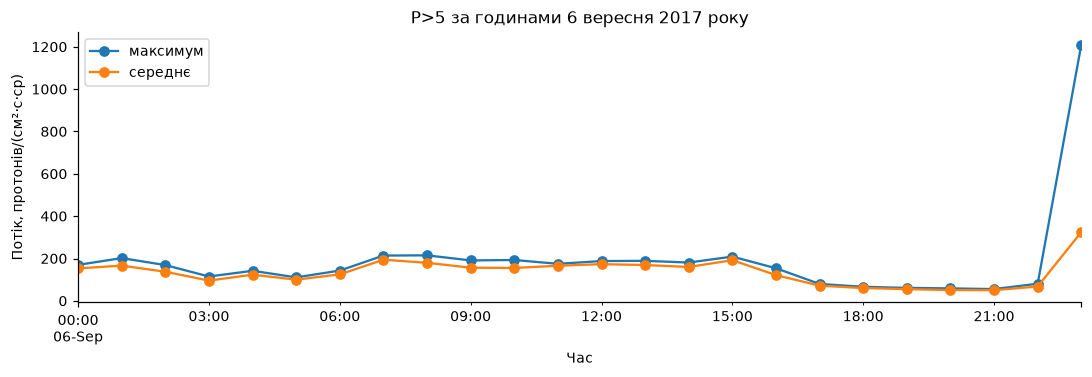

In [19]:
selected_day = A[(A["ts"] >= "2017-09-06") & (A["ts"] < "2017-09-07")]
comparison = selected_day.set_index("ts")["p_gt_5"].resample("1h").agg(["max", "mean"])

ax = comparison.plot(figsize=(10, 3.5), marker="o")
ax.set(title="P>5 за годинами 6 вересня 2017 року",
       xlabel="Час", ylabel="Потік, протонів/(см²·с·ср)")
ax.legend(["максимум", "середнє"])
plt.tight_layout()
plt.show()

**Відповідь 4.2:** максимум не менший за середнє й сильніше реагує на короткі сплески:
о 23:00 різниця становить 885,33 протонів/(см²·с·ср) (1210 проти 324,68).
Вона стає суттєвою, коли всередині години є короткий пік, який середнє згладжує.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [20]:
# Кожне добове значення F10.7 поширюємо на всі 24 години відповідної доби.
b_hours = pd.date_range(B["ts"].min(), B["ts"].max() + pd.Timedelta(hours=23), freq="1h")
B_hourly = (B.set_index("ts")[["rfu"]]
              .reindex(b_hours)
              .ffill()
              .rename_axis("ts")
              .reset_index())

C_hourly = C[["ts", "speed", "density"]]

M_inner = (A_hourly.merge(C_hourly, on="ts", how="inner")
                    .merge(B_hourly, on="ts", how="inner"))
M_outer = (A_hourly.merge(C_hourly, on="ts", how="outer")
                    .merge(B_hourly, on="ts", how="outer")
                    .sort_values("ts"))

print("inner:", M_inner.shape, "outer:", M_outer.shape)
M = M_inner.copy()
print("Рядки з хоча б одним пропуском:")
display(M[M.isna().any(axis=1)])

inner: (600, 20) outer: (601, 20)
Рядки з хоча б одним пропуском:


,ts,p_gt_1_mean,p_gt_1_max,p_gt_5_mean,p_gt_5_max,p_gt_10_mean,p_gt_10_max,p_gt_30_mean,p_gt_30_max,p_gt_50_mean,p_gt_50_max,p_gt_100_mean,p_gt_100_max,e_gt_0.8_mean,e_gt_0.8_max,e_gt_2.0_mean,e_gt_2.0_max,speed,density,rfu
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.134,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,NaN,NaN,140.0
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.134,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,NaN,NaN,140.0
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.134,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,NaN,NaN,140.0
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.120,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,NaN,NaN,140.0
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.110,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,NaN,NaN,140.0
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.144,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,NaN,NaN,140.0
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.159,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,NaN,NaN,140.0
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.166,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,NaN,NaN,140.0


**Відповідь 4.3:** `inner` дає 600 спільних годин, а `outer` — 601 рядок,
бо таблиця C має ще вимірювання за 22 вересня 00:00, якого немає в A та B.
Обрано `inner`, щоб аналізувати тільки години, для яких часовий інтервал представлений
у всіх трьох джерелах; наявні всередині інтервалу пропуски вітру залишено як `NaN`.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [21]:
M["група"] = pd.cut(
    M["p_gt_10_max"],
    bins=[-np.inf, 10, 1000, np.inf],
    right=False,
    labels=["тиха", "активна", "дуже активна"]
)
group_counts = M["група"].value_counts().reindex(["тиха", "активна", "дуже активна"])
print(group_counts)

група
тиха            411
активна         171
дуже активна     18
Name: count, dtype: int64


**Самоперевірка етапу 4.**

In [22]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 600 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

Середнє: 156.590; медіана: 0.601


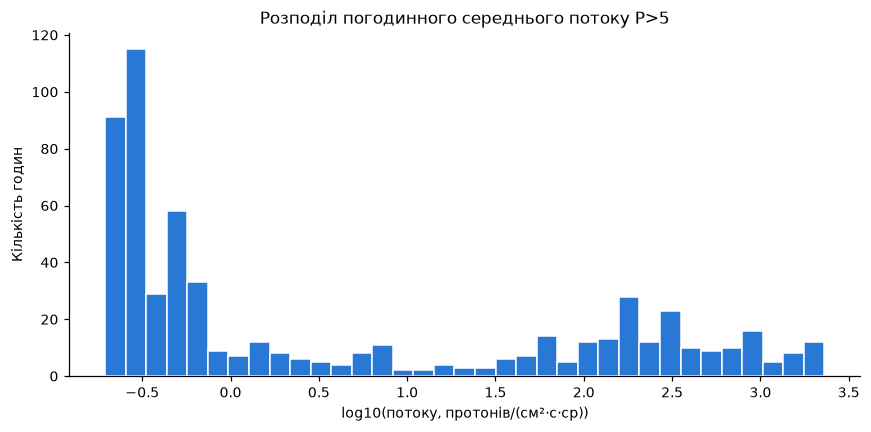

In [23]:
flux_column = "p_gt_5_mean"
p5_mean = M[flux_column].mean()
p5_median = M[flux_column].median()
print(f"Середнє: {p5_mean:.3f}; медіана: {p5_median:.3f}")

positive_values = M.loc[M[flux_column] > 0, flux_column]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(positive_values), bins=35, color="#2a78d6", edgecolor="white")
ax.set(title="Розподіл погодинного середнього потоку P>5",
       xlabel="log10(потоку, протонів/(см²·с·ср))", ylabel="Кількість годин")
plt.tight_layout()
plt.show()

**Висновок:** середнє P>5 дорівнює 156,59, а медіана лише 0,601 протонів/(см²·с·ср),
тобто середнє у 260 разів більше, бо невелика кількість годин із дуже великими
сплесками формує довгий правий хвіст розподілу.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

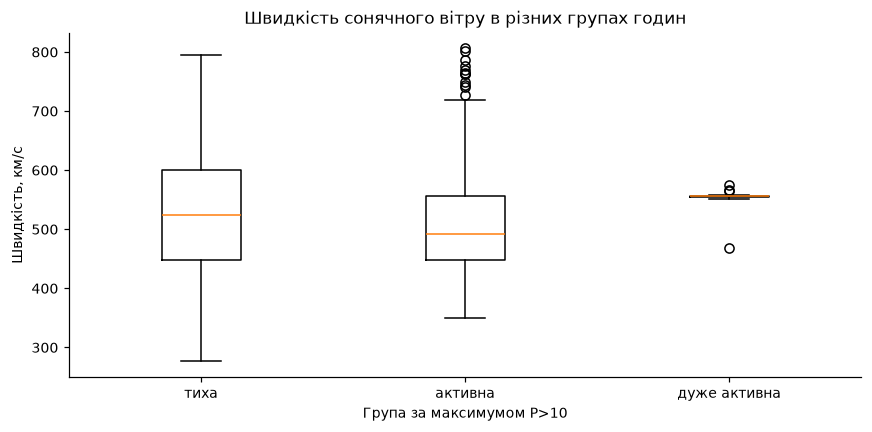

група
тиха            524.0
активна         492.0
дуже активна    556.0
Name: speed, dtype: float64


In [24]:
group_order = ["тиха", "активна", "дуже активна"]
boxplot_data = [M.loc[M["група"] == group, "speed"].dropna() for group in group_order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(boxplot_data, tick_labels=group_order, showfliers=True)
ax.set(title="Швидкість сонячного вітру в різних групах годин",
       xlabel="Група за максимумом P>10", ylabel="Швидкість, км/с")
plt.tight_layout()
plt.show()

print(M.groupby("група", observed=True)["speed"].median())

**Висновок:** медіанна швидкість вітру становить 524 км/с у тихі години,
492 км/с в активні та 556 км/с у дуже активні; розподіли сильно перекриваються,
тому сама швидкість вітру не дає чіткого поділу цих груп.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Коефіцієнт кореляції Пірсона: -0.041


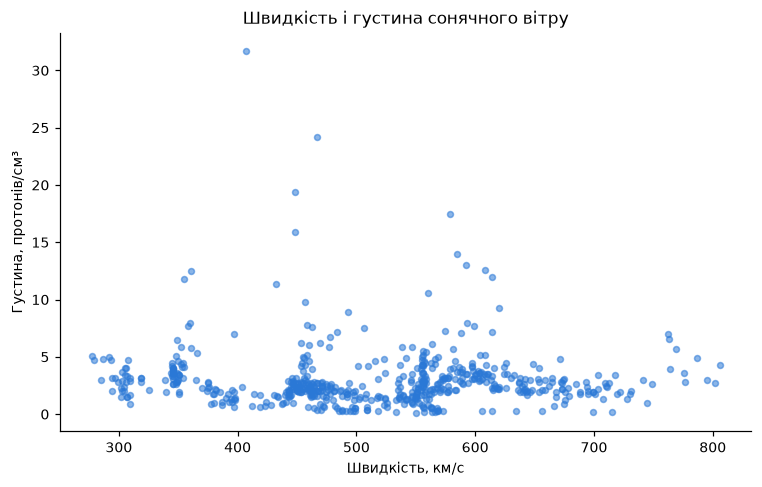

In [25]:
pair_data = M[["speed", "density"]].dropna()
correlation = pair_data.corr().iloc[0, 1]
print(f"Коефіцієнт кореляції Пірсона: {correlation:.3f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(pair_data["speed"], pair_data["density"], s=15, alpha=0.55, color="#2a78d6")
ax.set(title="Швидкість і густина сонячного вітру",
       xlabel="Швидкість, км/с", ylabel="Густина, протонів/см³")
plt.tight_layout()
plt.show()

**Висновок:** коефіцієнт кореляції між швидкістю та густиною дорівнює −0,041,
а хмара точок не має виразного нахилу, тому лінійного зв’язку в цьому вікні майже немає.

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

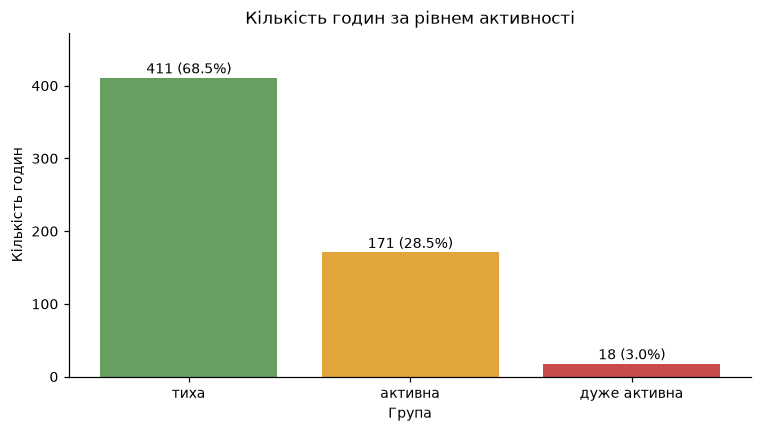

In [26]:
group_counts = M["група"].value_counts().reindex(["тиха", "активна", "дуже активна"])
percentages = group_counts / len(M) * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(group_counts.index.astype(str), group_counts.values,
              color=["#66a061", "#e2a53b", "#c84b4b"])
for bar, n, p in zip(bars, group_counts, percentages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 6,
            f"{n} ({p:.1f}%)", ha="center")
ax.set(title="Кількість годин за рівнем активності",
       xlabel="Група", ylabel="Кількість годин")
ax.set_ylim(0, group_counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Висновок:** із 600 годин 411 (68,5%) були тихими, 171 (28,5%) — активними,
і лише 18 (3,0%) — дуже активними.

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

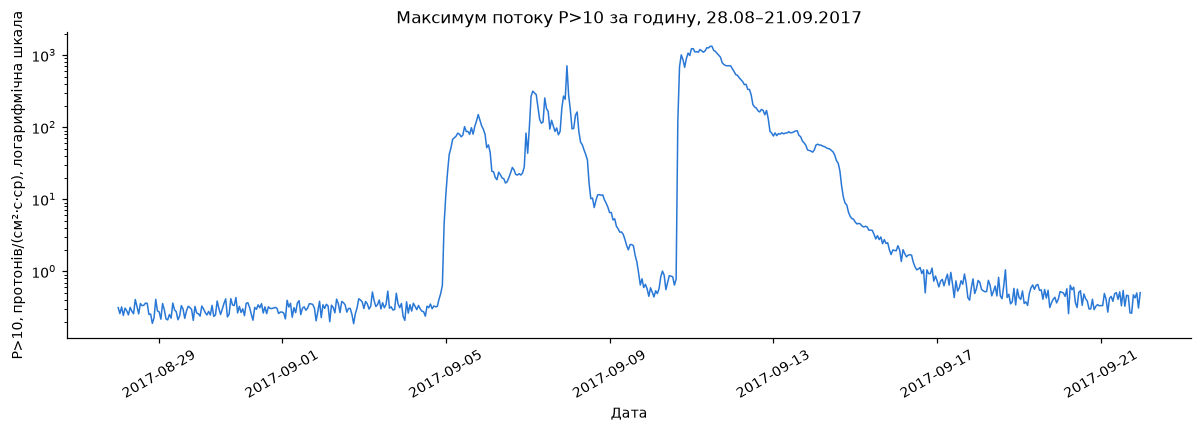

ts             2017-09-11 11:00:00
p_gt_10_max                 1330.0
Name: 347, dtype: object


In [27]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(M["ts"], M["p_gt_10_max"], color="#2a78d6", linewidth=1)
ax.set_yscale("log")
ax.set(title="Максимум потоку P>10 за годину, 28.08–21.09.2017",
       xlabel="Дата", ylabel="P>10, протонів/(см²·с·ср), логарифмічна шкала")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print(M.loc[M["p_gt_10_max"].idxmax(), ["ts", "p_gt_10_max"]])

**Висновок:** найбільший погодинний максимум P>10 — 1330 протонів/(см²·с·ср)
11 вересня о 11:00; основне підвищення тривало приблизно 6–14 вересня, тоді як
на початку й наприкінці періоду потік був на порядки нижчим.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

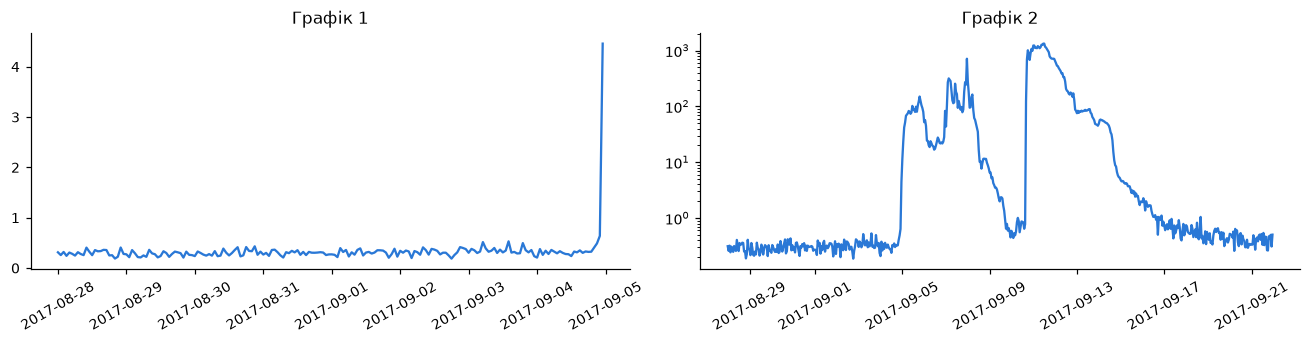

In [28]:
COLUMN = 'p_gt_10_max'   # <- впишіть назву свого стовпця з МАКСИМУМОМ P>10 за годину

window = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(window['ts'], window[COLUMN], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[COLUMN], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. З першого графіка можна вирішити, що до 4 вересня космічна погода була переважно спокійною і значних подій не сталося.
2. Другий графік показує повний період: після 5 вересня було кілька сильних сплесків, а максимум P>10 припав на 11 вересня.
3. Перший графік охоплює лише 28 серпня — 4 вересня та має лінійну вісь Y; другий охоплює всі 25 діб і використовує логарифмічну вісь Y. Отже, різняться часовий інтервал і масштаб осі.

### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

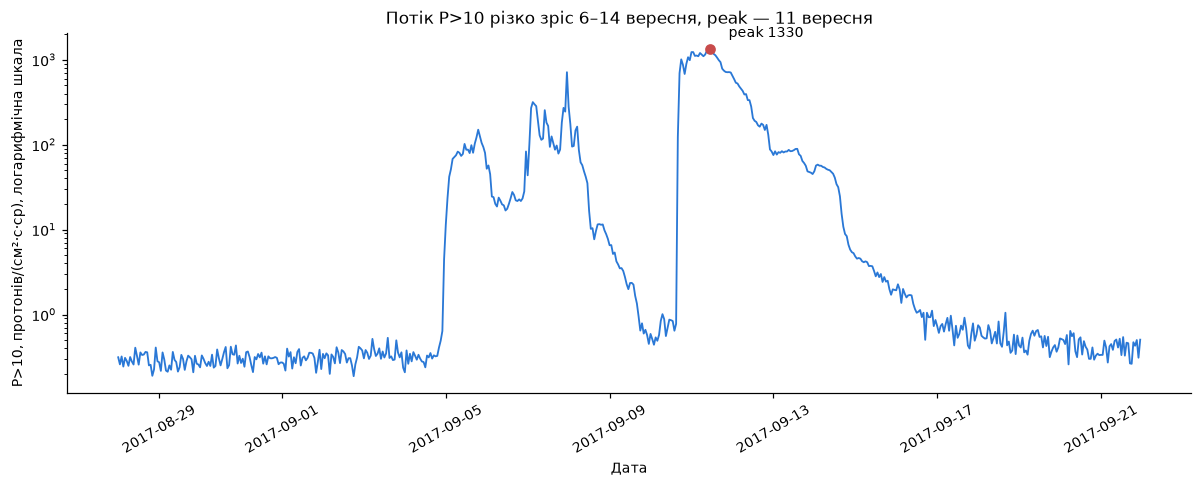

In [29]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(M["ts"], M["p_gt_10_max"], color="#2a78d6", linewidth=1.2)
ax.set_yscale("log")
peak = M.loc[M["p_gt_10_max"].idxmax()]
ax.scatter([peak["ts"]], [peak["p_gt_10_max"]], color="#c84b4b", zorder=3)
ax.annotate(f"peak {peak['p_gt_10_max']:.0f}", (peak["ts"], peak["p_gt_10_max"]),
            xytext=(12, 8), textcoords="offset points")
ax.set(title="Потік P>10 різко зріс 6–14 вересня, peak — 11 вересня",
       xlabel="Дата", ylabel="P>10, протонів/(см²·с·ср), логарифмічна шкала")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Відповідь 6.2:** я показав увесь доступний період і використав логарифмічну шкалу,
бо значення відрізняються на кілька порядків. Так видно і звичайний фон, і сильні
сплески без приховування частини дат; окремо позначено глобальний максимум.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:** середнє погодинного P>5 (156,59) у 260 разів перевищує медіану
(0,601), що видно з гістограми 1: розподіл має дуже довгий правий хвіст.

**Спостереження 2:** 411 із 600 годин (68,5%) були тихими, а дуже активними — лише
18 годин (3,0%); це видно зі стовпчикової діаграми 4.

**Спостереження 3:** швидкість і густина сонячного вітру майже не мають лінійного
зв’язку: `r = −0,041`, що показують розрахунок і діаграма розсіювання 3.

### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [30]:
missing_rows = M.isna().any(axis=1).sum()
missing_share = M.isna().any(axis=1).mean()
print(f"Рядків із пропуском: {missing_rows} з {len(M)}")
print(f"Частка: {missing_share:.4f} = {missing_share:.2%}")
display(M.loc[M.isna().any(axis=1), ["ts", "speed", "density"]])

Рядків із пропуском: 8 з 600
Частка: 0.0133 = 1.33%


,ts,speed,density
175,2017-09-04 07:00:00,NaN,NaN
176,2017-09-04 08:00:00,NaN,NaN
177,2017-09-04 09:00:00,NaN,NaN
178,2017-09-04 10:00:00,NaN,NaN
179,2017-09-04 11:00:00,NaN,NaN
180,2017-09-04 12:00:00,NaN,NaN
181,2017-09-04 13:00:00,NaN,NaN
182,2017-09-04 14:00:00,NaN,NaN


**Відповідь 7.2:** хоча б один пропуск мають 8 із 600 рядків об’єднаної таблиці,
тобто **1,33%**. Усі вони припадають на 4 вересня 07:00–14:00 і пов’язані з
одночасно відсутніми значеннями швидкості та густини сонячного вітру.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [31]:
ІНСТРУМЕНТИ_ШІ = 'OpenAI Codex (ChatGPT)'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'синтаксис',
    'етап 3, паспорт даних і дивні значення':     'код, перевірено',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'текст, як є',
    'етапи 6–7, порівняння графіків і спостереження': 'текст, як є',
}

ЩО_ПЕРЕВІРЕНО = (
    'Ноутбук виконано згори донизу на чистому ядрі. Звірено 7200, 25 і 601 рядок '
    'у трьох таблицях, 600 рядків після inner-об’єднання, 8 рядків із пропусками, '
    'кількості груп 411/171/18, кореляцію −0,041 та максимум P>10 = 1330.'
)

ПІДТВЕРДЖУЮ = True

In [32]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Кузнєцов Макар
інструменти:                                   OpenAI Codex (ChatGPT)
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    синтаксис
етап 3, паспорт даних і дивні значення:        код, перевірено
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                текст, як є
етапи 6–7, порівняння графіків і спостереження: текст, як є
------------------------------------------------------------------------------
перевірено автором:
Ноутбук виконано згори донизу на чистому ядрі. Звірено 7200, 25 і 601 рядок у трьох таблицях, 600 рядків після inner-об’єднання, 8 рядків із пропусками, кількості груп 411/171/18, кореляцію −0,041 та максимум P>10 = 1330.
Автор підтверджує, що може пояснити кожен рядок коду під ча

---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [33]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (600, 21)


In [34]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
